DATA PREPROCESSING AND FEATURE ENGINEERING IN MACHINE LEARNING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1.	Handle missing values as per the best practices (imputation, removal, etc.).        
●	Apply scaling techniques to numerical features:     
a.	Standard Scaling   b. Min-Max Scaling       
●	Discuss the scenarios where each scaling technique is preferred and why.


In [2]:
df=pd.read_csv("adult_with_headers (1).csv")

In [3]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education_num   32561 non-null  int64
 5   marital_status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital_gain    32561 non-null  int64
 11  capital_loss    32561 non-null  int64
 12  hours_per_week  32561 non-null  int64
 13  native_country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.5 MB


In [5]:
df.duplicated().sum()

np.int64(24)

In [6]:
df.drop_duplicates(inplace=True)

In [7]:
df.duplicated().sum()

np.int64(0)

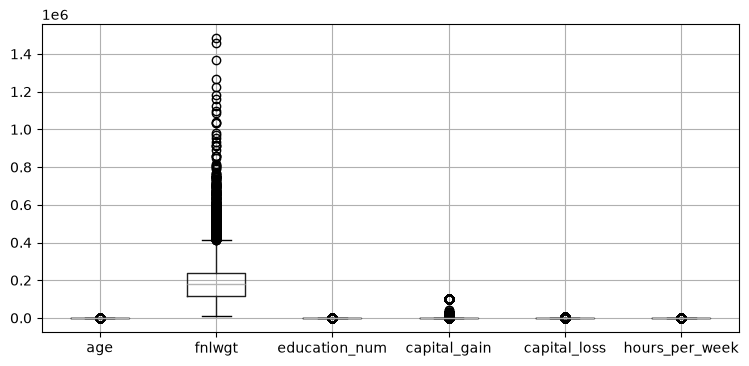

In [8]:
plt.figure(figsize=(9,4))
df.boxplot()
plt.show()

In [9]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(include=['int','float']).columns:
    outlier_capping(df,col)

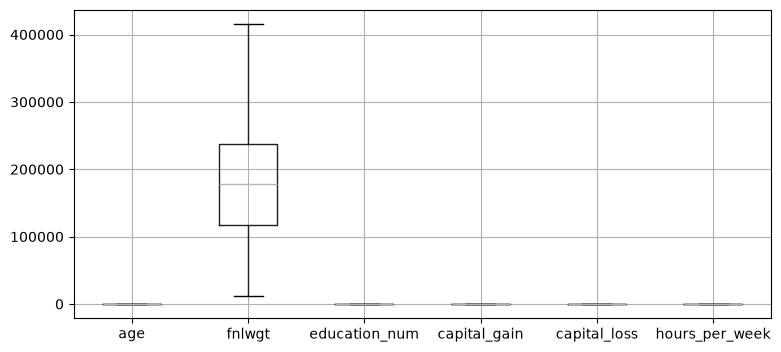

In [10]:
plt.figure(figsize=(9,4))
df.boxplot()
plt.show()

In [11]:
from sklearn.impute import SimpleImputer

In [12]:
df=df.replace(' ?',np.nan)

In [13]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     582
income               0
dtype: int64

In [14]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='str')

In [15]:
cols_with_missing_vals=['workclass','occupation','native_country']

In [16]:
imputer=SimpleImputer(strategy='most_frequent')

In [17]:
df[cols_with_missing_vals]=imputer.fit_transform(df[cols_with_missing_vals])

In [18]:
df.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [19]:
#applying scaling techniques
from sklearn.preprocessing import StandardScaler,MinMaxScaler,LabelEncoder,OneHotEncoder

In [20]:
num_cols=df.select_dtypes(include=['int64','float64']).columns

In [21]:
std_sca=StandardScaler()
df_std_scaled=pd.DataFrame(std_sca.fit_transform(df[num_cols]),columns=num_cols)

In [22]:
df_std_scaled

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,0.032472,-1.149209,1.168918,0.0,0.0,-0.194472
1,0.844002,-1.088284,1.168918,0.0,0.0,-1.406640
2,-0.041304,0.303007,-0.457496,0.0,0.0,-0.194472
3,1.065329,0.503550,-1.270703,0.0,0.0,-0.194472
4,-0.779058,1.593665,1.168918,0.0,0.0,-0.194472
...,...,...,...,...,...,...
32532,-0.852834,0.740954,0.762315,0.0,0.0,-0.517717
32533,0.106247,-0.341170,-0.457496,0.0,0.0,-0.194472
32534,1.434206,-0.367075,-0.457496,0.0,0.0,-0.194472
32535,-1.221711,0.154180,-0.457496,0.0,0.0,-1.406640


In [23]:
mm_scaler=MinMaxScaler()
df_mm_scaled=pd.DataFrame(mm_scaler.fit_transform(df[num_cols]),columns=num_cols)

In [24]:
df_mm_scaled

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,0.360656,0.161680,0.739130,0.0,0.0,0.375
1,0.540984,0.176044,0.739130,0.0,0.0,0.000
2,0.344262,0.504046,0.391304,0.0,0.0,0.375
3,0.590164,0.551325,0.217391,0.0,0.0,0.375
4,0.180328,0.808324,0.739130,0.0,0.0,0.375
...,...,...,...,...,...,...
32532,0.163934,0.607294,0.652174,0.0,0.0,0.275
32533,0.377049,0.352179,0.391304,0.0,0.0,0.375
32534,0.672131,0.346072,0.391304,0.0,0.0,0.375
32535,0.081967,0.468960,0.391304,0.0,0.0,0.000


In [25]:
print("Standard scaling transforms data to have a mean of 0 and a standard deviation of 1.\nMin-Max scaling shrinks the data range to a strict boundary, typically between 0 and 1.")

Standard scaling transforms data to have a mean of 0 and a standard deviation of 1.
Min-Max scaling shrinks the data range to a strict boundary, typically between 0 and 1.


2. Encoding Techniques:     
●	Apply One-Hot Encoding to categorical variables with less than 5 categories.        
●	Use Label Encoding for categorical variables. Data Exploration and Preprocessing:       
●	Load the dataset and conduct basic data exploration (summary statistics, missing values, data types).       
●	les with more than 5 categories.        
●	Discuss the pros and cons of One-Hot Encoding and Label Encoding.


In [26]:
cat_cols=df.select_dtypes(include=['object']).columns

C:\Users\pprem\AppData\Local\Temp\ipykernel_14008\22036366.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols=df.select_dtypes(include=['object']).columns


In [27]:
#Separating columns based on the < 5 categories rule
ohe_cols=[col for col in cat_cols if df[col].nunique() < 5]
le_cols=[col for col in cat_cols if df[col].nunique() >= 5]

In [28]:
#apply one_hot encoding
encoder=OneHotEncoder(sparse_output=False, drop='first')

encoded_array=encoder.fit_transform(df[ohe_cols])

encoded_col_names=encoder.get_feature_names_out(ohe_cols)

encoded_df=pd.DataFrame(encoded_array, columns=encoded_col_names, index=df.index)

df=df.drop(columns=ohe_cols)
df=pd.concat([df, encoded_df], axis=1)
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,0.0,0.0,40.0,United-States,1.0,0.0
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,0.0,0.0,32.5,United-States,1.0,0.0
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,0.0,0.0,40.0,United-States,1.0,0.0
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,0.0,0.0,40.0,United-States,1.0,0.0
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,0.0,0.0,40.0,Cuba,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,Private,257302.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,0.0,0.0,38.0,United-States,0.0,0.0
32557,40.0,Private,154374.0,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,0.0,0.0,40.0,United-States,1.0,1.0
32558,58.0,Private,151910.0,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,0.0,0.0,40.0,United-States,0.0,0.0
32559,22.0,Private,201490.0,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,0.0,0.0,32.5,United-States,1.0,0.0


In [29]:
#Label Encoder
le=LabelEncoder()

In [30]:
for col in le_cols:
    df[col]=le.fit_transform(df[col])

In [31]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K
0,39.0,6,77516.0,9,13.0,4,0,1,4,0.0,0.0,40.0,38,1.0,0.0
1,50.0,5,83311.0,9,13.0,2,3,0,4,0.0,0.0,32.5,38,1.0,0.0
2,38.0,3,215646.0,11,9.0,0,5,1,4,0.0,0.0,40.0,38,1.0,0.0
3,53.0,3,234721.0,1,7.0,2,5,0,2,0.0,0.0,40.0,38,1.0,0.0
4,28.0,3,338409.0,9,13.0,2,9,5,2,0.0,0.0,40.0,4,0.0,0.0


In [32]:
print(""" 
One-Hot Encoding

Pros: It creates a binary column for each category, preventing the machine learning model from assuming a false numerical ranking.
Cons: It significantly expands the dataset's dimensionality

Label Encoding

Pros: It is highly memory efficient. By replacing text categories with simple integers (0, 1, 2, 3) in a single column, it keeps the feature space small.
Cons: It introduces unintended mathematical relationships.

""")

 
One-Hot Encoding

Pros: It creates a binary column for each category, preventing the machine learning model from assuming a false numerical ranking.
Cons: It significantly expands the dataset's dimensionality

Label Encoding

Pros: It is highly memory efficient. By replacing text categories with simple integers (0, 1, 2, 3) in a single column, it keeps the feature space small.
Cons: It introduces unintended mathematical relationships.




3. Feature Engineering:     
●	Create at least 2 new features that could be beneficial for the model. Explain the rationale behind your choices.       
●	Apply a transformation (e.g., log transformation) to at least one skewed numerical feature and justify your choice.


In [33]:
#creating features
df['net_capital']=df['capital_gain']-df['capital_loss'] #feature 1

In [34]:
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K,net_capital
0,39.0,6,77516.0,9,13.0,4,0,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0
1,50.0,5,83311.0,9,13.0,2,3,0,4,0.0,0.0,32.5,38,1.0,0.0,0.0
2,38.0,3,215646.0,11,9.0,0,5,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0
3,53.0,3,234721.0,1,7.0,2,5,0,2,0.0,0.0,40.0,38,1.0,0.0,0.0
4,28.0,3,338409.0,9,13.0,2,9,5,2,0.0,0.0,40.0,4,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,3,257302.0,7,12.0,2,12,5,4,0.0,0.0,38.0,38,0.0,0.0,0.0
32557,40.0,3,154374.0,11,9.0,2,6,0,4,0.0,0.0,40.0,38,1.0,1.0,0.0
32558,58.0,3,151910.0,11,9.0,6,0,4,4,0.0,0.0,40.0,38,0.0,0.0,0.0
32559,22.0,3,201490.0,11,9.0,4,0,3,4,0.0,0.0,32.5,38,1.0,0.0,0.0


In [35]:
#feature 2
df['is_married']=df['marital_status'].apply(lambda x: 1 if x in [1, 2, 3] else 0)

In [36]:
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K,net_capital,is_married
0,39.0,6,77516.0,9,13.0,4,0,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0,0
1,50.0,5,83311.0,9,13.0,2,3,0,4,0.0,0.0,32.5,38,1.0,0.0,0.0,1
2,38.0,3,215646.0,11,9.0,0,5,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0,0
3,53.0,3,234721.0,1,7.0,2,5,0,2,0.0,0.0,40.0,38,1.0,0.0,0.0,1
4,28.0,3,338409.0,9,13.0,2,9,5,2,0.0,0.0,40.0,4,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,3,257302.0,7,12.0,2,12,5,4,0.0,0.0,38.0,38,0.0,0.0,0.0,1
32557,40.0,3,154374.0,11,9.0,2,6,0,4,0.0,0.0,40.0,38,1.0,1.0,0.0,1
32558,58.0,3,151910.0,11,9.0,6,0,4,4,0.0,0.0,40.0,38,0.0,0.0,0.0,0
32559,22.0,3,201490.0,11,9.0,4,0,3,4,0.0,0.0,32.5,38,1.0,0.0,0.0,0


In [37]:
#Applying a transformation (e.g., log transformation) to at least one skewed numerical feature
df['fnlwgt_log']=np.log1p(df['fnlwgt'])

In [38]:
df

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,sex_ Male,income_ >50K,net_capital,is_married,fnlwgt_log
0,39.0,6,77516.0,9,13.0,4,0,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0,0,11.258253
1,50.0,5,83311.0,9,13.0,2,3,0,4,0.0,0.0,32.5,38,1.0,0.0,0.0,1,11.330348
2,38.0,3,215646.0,11,9.0,0,5,1,4,0.0,0.0,40.0,38,1.0,0.0,0.0,0,12.281398
3,53.0,3,234721.0,1,7.0,2,5,0,2,0.0,0.0,40.0,38,1.0,0.0,0.0,1,12.366157
4,28.0,3,338409.0,9,13.0,2,9,5,2,0.0,0.0,40.0,4,0.0,0.0,0.0,1,12.732013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,3,257302.0,7,12.0,2,12,5,4,0.0,0.0,38.0,38,0.0,0.0,0.0,1,12.458010
32557,40.0,3,154374.0,11,9.0,2,6,0,4,0.0,0.0,40.0,38,1.0,1.0,0.0,1,11.947140
32558,58.0,3,151910.0,11,9.0,6,0,4,4,0.0,0.0,40.0,38,0.0,0.0,0.0,0,11.931050
32559,22.0,3,201490.0,11,9.0,4,0,3,4,0.0,0.0,32.5,38,1.0,0.0,0.0,0,12.213500
